The goal ofthis assignment is to use the Breast Cancer Wisconsin (Diagnostic) dataset to predict whether breast cancer tumors are benign or malignant

In [1]:
#InstallXGBoost
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\tebos\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [1]:
#importthe necessar libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
# Load Breast Cancer Wisconsin dataset
cancer = load_breast_cancer()

# Convert features into a DataFrame
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Target variable
y = pd.Series(cancer.target, name="target")

# Display first five rows
print(X.head())

# Display target classes
print("Target classes:", cancer.target_names)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

Note that the purpose is to predict whether a tumor is malignant (cancerous) or benign (non cancerous).

**Split the dataset into training and testing sets**

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training features: (455, 30)
Testing features: (114, 30)

Training class distribution:
target
1    285
0    170
Name: count, dtype: int64

Testing class distribution:
target
1    72
0    42
Name: count, dtype: int64


**Explore the data by checking its shape, feature names, and basic statistics**

In [5]:
print("Dataset shape:", X.shape)

print("\nFeature names:")
print(X.columns.tolist())

print("\nData information:")
X.info()

# Summary statistics of training data
print(X_train.describe().T)

# Check missing values
print("\nMissing values:")
print(X_train.isnull().sum())

# Check target distribution
print("\nTarget distribution:")
print(y_train.value_counts())

Dataset shape: (569, 30)

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Data information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64


**Implement Random Forest**

In [6]:
# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate model
print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Malignant", "Benign"]
))

Random Forest Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



The Random Forest model archived an overall accuracy of 96%. The model performed slightly better at identifying benign tumors, with a recall of 97%, compared to 93% for malignant tumors. The malignant F1-score of 94% indicates a strong balance between precision and recall. 

In [12]:
#Calculate evaluation Metrics
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, pos_label=0)
rf_recall = recall_score(y_test, rf_pred, pos_label=0)
rf_f1 = f1_score(y_test, rf_pred, pos_label=0)

print("Random Forest Performance:")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")

Random Forest Performance:
Accuracy:  0.9561
Precision: 0.9512
Recall:    0.9286
F1-score:  0.9398


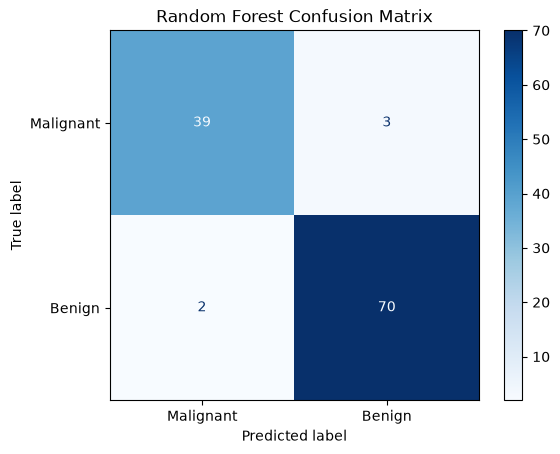

In [13]:
#Random forest confusion atrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

The Random Forest confusion matrix had an overall accuracy of 95.61%. Out of 114 test samples, the model correctly classified 39 malignant tumors and 70 benign tumors. However, 3 malignant tumors were incorrectly classified as benign (false negatives), while 2 benign tumors were incorrectly classified as malignant (false positives).

**Implement XGBoost**

In [8]:
# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train, y_train)

# Predictions
xgb_pred = xgb_model.predict(X_test)

# Classification report
print("XGBoost Classification Report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["Malignant", "Benign"]
))

XGBoost Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.90      0.93        42
      Benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



The XGBoost model achieved an overall accuracy of 95%. For malignant tumors, the model achieved 95% precision, 90% recall, and a 93% F1-score, indicating that it correctly identified most cancerous tumors but missed approximately 10%. For benign tumors, the model achieved 95% precision, 97% recall, and a 96% F1-score.

Note that the When compared with Random Forest, which achieved 96% accuracy and 93% malignant recall, XGBoost performed slightly worse than the Random forest 

In [10]:
#Evaluate XGBoost
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred, pos_label=0)
xgb_recall = recall_score(y_test, xgb_pred, pos_label=0)
xgb_f1 = f1_score(y_test, xgb_pred, pos_label=0)

print("XGBoost Performance:")
print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-score:  {xgb_f1:.4f}")

XGBoost Performance:
Accuracy:  0.9474
Precision: 0.9500
Recall:    0.9048
F1-score:  0.9268


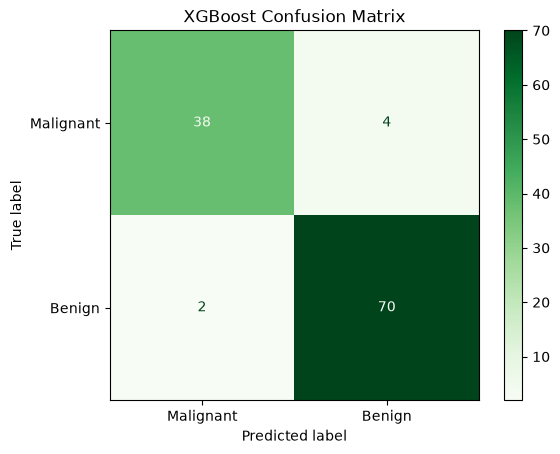

In [11]:
#XGBOost Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Greens"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

The XGBoost confusion matrix had an overall accuracy of 94.74%. Out of 114 test samples, the model correctly classified 38 malignant tumors and 70 benign tumors. However, 4 malignant tumors were incorrectly classified as benign (false negatives), while 2 benign tumors were incorrectly classified as malignant (false positives).

**Compare Random Forest and XGBoost**

In [14]:
results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [rf_accuracy, xgb_accuracy],
    "Precision": [rf_precision, xgb_precision],
    "Recall": [rf_recall, xgb_recall],
    "F1-score": [rf_f1, xgb_f1]
})

print(results.round(4))

           Model  Accuracy  Precision  Recall  F1-score
0  Random Forest    0.9561     0.9512  0.9286    0.9398
1        XGBoost    0.9474     0.9500  0.9048    0.9268


Based on the ouputs, the Random Forest achieved slightly better classification performance across all evaluation metrics than XGBoost. Random Forest recorded an accuracy of 95.61%, precision of 95.12%, recall of 92.86%, and F1-score of 93.98%. In comparison, XGBoost achieved an accuracy of 94.74%, precision of 95.00%, recall of 90.48%, and F1-score of 92.68%.

**Hyperparameter Tuning using Grid Search with 5-fold cross valiadation**

In [15]:
#Definding Parameter for Random Forest

from sklearn.metrics import make_scorer

# Optimize F1-score for malignant tumors (class 0)
malignant_f1 = make_scorer(f1_score, pos_label=0)

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=5,
    scoring=malignant_f1,
    n_jobs=-1
)

# Fit using training data only
rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(rf_grid.best_score_)

Best Random Forest Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation F1-score:
0.9469344254621787


In [16]:
#Evaluate Tune Random Forest
rf_tuned = rf_grid.best_estimator_

rf_tuned_pred = rf_tuned.predict(X_test)

print("Tuned Random Forest Classification Report:")
print(classification_report(
    y_test,
    rf_tuned_pred,
    target_names=["Malignant", "Benign"]
))

Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



The Tuned Random Forest model archieved an overall accuracy of 96% just like the Random forest classification model.

**Hyperparameter tuning for XGBoost**

In [17]:
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.01, 0.1],
    "subsample": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_grid=xgb_param_grid,
    cv=5,
    scoring=malignant_f1,
    n_jobs=-1
)

# Train Grid Search
xgb_grid.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(xgb_grid.best_score_)

Best XGBoost Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}

Best Cross-Validation F1-score:
0.9668888757792067


In [18]:
#Evaluate the Tuned XGBoost
xgb_tuned = xgb_grid.best_estimator_

xgb_tuned_pred = xgb_tuned.predict(X_test)

print("Tuned XGBoost Classification Report:")
print(classification_report(
    y_test,
    xgb_tuned_pred,
    target_names=["Malignant", "Benign"]
))

Tuned XGBoost Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.90      0.93        42
      Benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [19]:
#Compare the Tuned Model
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, pos_label=0
        )
    }

comparison = pd.DataFrame([
    evaluate_model("Random Forest", y_test, rf_pred),
    evaluate_model("Tuned Random Forest", y_test, rf_tuned_pred),
    evaluate_model("XGBoost", y_test, xgb_pred),
    evaluate_model("Tuned XGBoost", y_test, xgb_tuned_pred)
])

print(comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1-score
0        Random Forest    0.9561     0.9512  0.9286    0.9398
1  Tuned Random Forest    0.9561     0.9512  0.9286    0.9398
2              XGBoost    0.9474     0.9500  0.9048    0.9268
3        Tuned XGBoost    0.9474     0.9500  0.9048    0.9268


Based on the output, there was no effect with the hyperparameter tuning. Both algorithm achieved thesame result. However Overall, the Random Forest and XGBoost before and after hyperparameter tuning demonstrated that Random Forest achieved the best overall classification performance.

Random Forest recorded an accuracy of 95.61%, precision of 95.12%, recall of 92.86%, and F1-score of 93.98%. In comparison, XGBoost achieved an accuracy of 94.74%, precision of 95.00%, recall of 90.48%, and F1-score of 92.68%.